# Partie 8 · Une approche PINN (Physics-Informed Neural Network)

**Notations.** **MC** : modèle de connaissance (bilans de matière). **IA** : modèle guidé par les données (réseau de neurones). Les parties 1 à 7 citées ci-dessous (cas test, IA pure, hybride série, etc.) sont dans le notebook `Synthese_modeles_hybrides`.

Dans les parties précédentes, la physique entrait dans le modèle par sa **structure** (hybride série : un réseau fournit $\mu$ aux bilans). Dans un **PINN**, la physique entre par le **critère d'apprentissage** : un réseau représente directement la **trajectoire** $t\mapsto(X(t),S(t))$, et on pénalise le non-respect des équations de bilan.

| | Hybride série (partie 4) | PINN (cette partie) |
|---|---|---|
| Ce que représente le réseau | $\mu$ (fonction de $\ln X,\ln S$) | la trajectoire $X(t),S(t)$ d'un essai, **et** $\mu(S)$ |
| Où est la physique | dans la structure (bilans intégrés) | dans le critère (résidu des bilans) |
| Ce que le réseau voit | l'état mesuré (bruité) à $t_k$ | tous les instants, y compris **entre** les mesures |
| Conservation de la matière | exacte | favorisée, non garantie |

**Principe (problème inverse).** Pour chaque essai $r$, un petit réseau $N_r(t)=(X_r,S_r)$ est ajusté aux mesures. Un réseau **commun** $\mu_\varphi(S)$ (même forme que le réseau de la partie 4, entrée $\ln S$ seule) intervient dans les bilans. Le critère est

$$J=\underbrace{\frac1{N_d}\sum\frac{(X-X_m)^2+(S-S_m)^2}{\sigma^2}}_{\text{données}}+\lambda\,\underbrace{\frac1{N_c}\sum\Big[\Big(\frac{r_X}{\rho}\Big)^2+\Big(\frac{r_S}{\rho}\Big)^2\Big]}_{\text{physique}},\qquad
\begin{cases}r_X=\dot X-(\mu_\varphi(S)-F/V)\,X\\ r_S=\dot S+k_1\mu_\varphi(S)X-(F/V)(S_{in}-S)\end{cases}$$

Les dérivées $\dot X,\dot S$ du réseau sont calculées **analytiquement**, aux **points de collocation** (4 par intervalle de 0,2 h, soit 4 000 points). Le gradient de $J$ par rapport à tous les poids, y compris les termes du second ordre (dérivée de $\dot X$ par rapport aux poids), est écrit **à la main** (NumPy seul) et vérifié par différences finies. L'optimiseur est **L-BFGS** de SciPy.

**Évaluation : exactement le protocole des parties 3 et 4.** Un PINN est entraîné sur des trajectoires d'apprentissage ; il ne « simule » pas un nouvel essai. On en retire donc le $\mu_\varphi(S)$ appris, que l'on **branche dans les mêmes bilans** que l'hybride série, puis on mesure l'erreur à un pas et en simulation libre sur les mêmes jeux de test (interpolation, extrapolation). Mêmes données, mêmes critères, mêmes repères (Monod, IA pure, hybride série, oracle).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

P = dict(mu_star=5.0, Km=10.0, Ki=0.1, k1=1.0, V0=10.0, dt=0.2, S_avg=60.0, floor=1e-3, mu_max=5/21)

def haldane(S, p=P):
    S = np.asarray(S, float); return p["mu_star"] * S / (p["Km"] + S + S**2 / p["Ki"])

def step_phys(X, S, V, F, Sin, mu, p=P):
    # bilans de matière intégrés exactement sur dt (mu, F, Sin constants)
    dt, k1 = p["dt"], p["k1"]; V1 = V + F * dt; e = np.exp(mu * dt)
    return X * e * V / V1, (S * V + F * Sin * dt - k1 * X * V * (e - 1)) / V1, V1

def act(a): return np.tanh(a / 2)       # sigmoïde symétrique (1-e^-a)/(1+e^-a)

In [2]:
class BlackBox:                       # IA pure 3 -> 8 -> 2 (partie 3)
    def __init__(self, seed, nh=8, p=P):
        rng = np.random.default_rng(seed); self.p = p
        self.W1 = rng.normal(0, .5, (3, nh)); self.b1 = np.zeros(nh); self.W2 = rng.normal(0, .5, (nh, 2)); self.b2 = np.zeros(2)
    def params(self): return [self.W1, self.b1, self.W2, self.b2]
    def features(self, X, S, Sin):
        f = self.p["floor"]; return np.column_stack([np.log(np.maximum(X, f)), np.log(np.maximum(S, f)), Sin / self.p["S_avg"]])
    def forward(self, Z):
        H = act(Z @ self.W1 + self.b1); return H, act(H @ self.W2 + self.b2)
    def predict(self, X, S, Sin, V=None, F=None):
        _, Y = self.forward(self.features(X, S, Sin)); return Y[:, 0] * self.p["S_avg"], Y[:, 1] * self.p["S_avg"]
    def loss_grad(self, idx, d):
        Z = self.features(d["X"][idx], d["S"][idx], d["Sin"][idx]); T = d["T"][idx]
        H, Y = self.forward(Z); E = Y - T; N = len(Z); L = np.mean(np.sum(E**2, axis=1))
        dA2 = (2 * E / N) * .5 * (1 - Y**2); dA1 = (dA2 @ self.W2.T) * .5 * (1 - H**2)
        return L, [Z.T @ dA1, dA1.sum(0), H.T @ dA2, dA2.sum(0)]

class HybridSerie:                    # réseau 2 -> 8 -> 1 + bilans de matière
    def __init__(self, seed, nh=8, p=P):
        rng = np.random.default_rng(seed); self.p = p
        self.W1 = rng.normal(0, .5, (2, nh)); self.b1 = np.zeros(nh); self.W2 = rng.normal(0, .5, (nh, 1)); self.b2 = np.zeros(1)
    def params(self): return [self.W1, self.b1, self.W2, self.b2]
    def features(self, X, S):
        f = self.p["floor"]; return np.column_stack([np.log(np.maximum(X, f)), np.log(np.maximum(S, f))])
    def mu(self, X, S):
        H = act(self.features(X, S) @ self.W1 + self.b1); mt = act(H @ self.W2 + self.b2)[:, 0]
        return 2 * self.p["mu_max"] * mt
    def predict(self, X, S, Sin, V, F):
        X1, S1, _ = step_phys(X, S, V, F, Sin, self.mu(X, S), self.p); return X1, S1
    def loss_grad(self, idx, d):
        p = self.p; X, S, Sin, V, F, T = (d[k][idx] for k in ("X", "S", "Sin", "V", "F", "T"))
        Z = self.features(X, S); H = act(Z @ self.W1 + self.b1); mt = act(H @ self.W2 + self.b2)[:, 0]
        mu = 2 * p["mu_max"] * mt
        X1, S1, V1 = step_phys(X, S, V, F, Sin, mu, p)
        E = np.column_stack([X1, S1]) / p["S_avg"] - T; N = len(X); L = np.mean(np.sum(E**2, axis=1))
        G1 = X1 * p["dt"]; G2 = -p["k1"] * X * V * p["dt"] * np.exp(mu * p["dt"]) / V1   # sensibilités
        dmu = (2 * E[:, 0] * G1 + 2 * E[:, 1] * G2) / p["S_avg"] / N                       # dL/dmu
        dA2 = (dmu * 2 * p["mu_max"] * .5 * (1 - mt**2))[:, None]
        dA1 = (dA2 @ self.W2.T) * .5 * (1 - H**2)
        return L, [Z.T @ dA1, dA1.sum(0), H.T @ dA2, dA2.sum(0)]

def train_model(net, d, tr, va, lr=0.02, max_epochs=30000, check=10, patience=40):
    prm = net.params(); m = [np.zeros_like(w) for w in prm]; v = [np.zeros_like(w) for w in prm]
    b1, b2, eps = .9, .999, 1e-8; best, best_params, best_ep, bad, hist = np.inf, None, 0, 0, []
    for ep in range(1, max_epochs + 1):
        L, g = net.loss_grad(tr, d)
        for i, (w, gi) in enumerate(zip(prm, g)):
            m[i] = b1 * m[i] + (1 - b1) * gi; v[i] = b2 * v[i] + (1 - b2) * gi**2
            w -= lr * (m[i] / (1 - b1**ep)) / (np.sqrt(v[i] / (1 - b2**ep)) + eps)
        if ep % check == 0:
            Lv, _ = net.loss_grad(va, d); hist.append((ep, L, Lv))
            if Lv < best: best, best_ep, bad, best_params = Lv, ep, 0, [w.copy() for w in prm]
            else:
                bad += 1
                if bad >= patience: break
    for w, bw in zip(prm, best_params): w[...] = bw
    return np.array(hist), best_ep, ep


In [3]:
def monod(S, mm, Ks): return mm * np.maximum(S, 0) / (Ks + np.maximum(S, 0))

def fit_monod(d):
    # MC : 2 paramètres identifiés par moindres carrés sur le critère à un pas
    def res(th):
        X1, S1, _ = step_phys(d["X"], d["S"], d["V"], d["F"], d["Sin"], monod(d["S"], *th))
        return (np.column_stack([X1, S1]) / P["S_avg"] - d["T"]).ravel()
    return least_squares(res, x0=[0.2, 1.0], bounds=([1e-4, 1e-4], [10, 100])).x

class HybridSerieS(HybridSerie):      # B' : le réseau ne reçoit que ln S
    def __init__(self, seed, nh=8, p=P):
        super().__init__(seed, nh, p); rng = np.random.default_rng(seed + 7)
        self.W1 = rng.normal(0, .5, (1, nh))
    def features(self, X, S):
        return np.log(np.maximum(S, self.p["floor"]))[:, None]

class MLP:                            # réseau générique, apprentissage par régression sur (Z, T)
    def __init__(self, seed, nin, nout, nh=8):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, .5, (nin, nh)); self.b1 = np.zeros(nh); self.W2 = rng.normal(0, .5, (nh, nout)); self.b2 = np.zeros(nout)
    def params(self): return [self.W1, self.b1, self.W2, self.b2]
    def forward(self, Z):
        H = act(Z @ self.W1 + self.b1); return H, act(H @ self.W2 + self.b2)
    def loss_grad(self, idx, d):
        Z, T = d["Z"][idx], d["T"][idx]; H, Y = self.forward(Z); E = Y - T; N = len(Z)
        dA2 = (2 * E / N) * .5 * (1 - Y**2); dA1 = (dA2 @ self.W2.T) * .5 * (1 - H**2)
        return np.mean(np.sum(E**2, axis=1)), [Z.T @ dA1, dA1.sum(0), H.T @ dA2, dA2.sum(0)]

LF = lambda v: np.log(np.maximum(v, P["floor"]))
R_MAX = 10.0      # g/L : amplitude maximale du résidu du parallèle

class SerieMCtoIA(MLP):             # A
    def __init__(self, seed, mc): super().__init__(seed, 5, 2); self.mc = mc
    def feats(self, X, S, Sin, V, F):
        Xt, St, _ = step_phys(X, S, V, F, Sin, monod(S, *self.mc))
        return np.column_stack([LF(X), LF(S), Sin / P["S_avg"], LF(Xt), LF(St)])
    def predict(self, X, S, Sin, V, F):
        Y = self.forward(self.feats(X, S, Sin, V, F))[1]; return Y[:, 0] * P["S_avg"], Y[:, 1] * P["S_avg"]

class Parallele(MLP):                 # C
    def __init__(self, seed, mc): super().__init__(seed, 3, 2); self.mc = mc
    def feats(self, X, S, Sin, V, F): return np.column_stack([LF(X), LF(S), Sin / P["S_avg"]])
    def predict(self, X, S, Sin, V, F):
        Xt, St, _ = step_phys(X, S, V, F, Sin, monod(S, *self.mc)); Y = self.forward(self.feats(X, S, Sin, V, F))[1]
        return Xt + R_MAX * Y[:, 0], St + R_MAX * Y[:, 1]

# vérification de gradient de MLP (utilisé par A et C)
chk = MLP(5, 5, 2); rng = np.random.default_rng(0); dd = dict(Z=rng.normal(size=(15, 5)), T=rng.uniform(-.2, .2, (15, 2))); ii = np.arange(15)
_, g = chk.loss_grad(ii, dd); worst = 0
for w, gw in zip(chk.params(), g):
    for ix in np.ndindex(w.shape):
        old = w[ix]; w[ix] = old + 1e-6; Lp, _ = chk.loss_grad(ii, dd); w[ix] = old - 1e-6; Lm, _ = chk.loss_grad(ii, dd); w[ix] = old
        fd = (Lp - Lm) / 2e-6; worst = max(worst, abs(fd - gw[ix]) / (abs(fd) + abs(gw[ix]) + 1e-12))
print(f"Gradient (réseaux de A et C) vs différences finies : erreur relative max = {worst:.1e}")

Gradient (réseaux de A et C) vs différences finies : erreur relative max = 1.5e-07


## Données et outils (identiques aux parties précédentes)

Mêmes essais d'apprentissage (11 essais, 1 000 intervalles, bruit $\sigma=0{,}1$ g/L), mêmes jeux de test d'interpolation et d'extrapolation.

In [4]:
def rhs(t, y, F, Sin, k1, kd):
    X, S, V = y; mu = float(haldane(max(S, 0.0)))
    return [mu * X - kd * X - F / V * X, -k1 * mu * X + F / V * (Sin - S), F]

def simulate(X0, S0, t_feed, t_total, rng, k1=1.0, kd=0.0):
    n = int(round(t_total / P["dt"])); n_feed = int(round(t_feed / P["dt"]))
    t = np.arange(n + 1) * P["dt"]; Y = np.zeros((n + 1, 3)); Y[0] = [X0, S0, P["V0"]]
    F = np.zeros(n); Sin = np.zeros(n); F[:n_feed] = 0.1; Sin[:n_feed] = rng.uniform(30.0, 90.0, n_feed)
    for k in range(n):
        Y[k+1] = solve_ivp(rhs, (0, P["dt"]), Y[k], method="LSODA", args=(F[k], Sin[k], k1, kd), rtol=1e-9, atol=1e-12).y[:, -1]
    return dict(t=t, X=Y[:, 0], S=Y[:, 1], V=Y[:, 2], F=F, Sin=Sin)

def add_noise(run, rng, sigma):
    r = dict(run)
    r["Xm"] = np.maximum(run["X"] + rng.normal(0, sigma, run["X"].shape), P["floor"])
    r["Sm"] = np.maximum(run["S"] + rng.normal(0, sigma, run["S"].shape), P["floor"])
    return r

def gen_train(k1=1.0, kd=0.0, sigma=0.1, seed=0, nseed=100):
    rng = np.random.default_rng(seed); runs = []
    for X0 in (0.1, 0.5, 0.9):
        for S0 in (0.1, 0.5, 0.9): runs.append(simulate(X0, S0, 15.0, 20.0, rng, k1, kd))
    for X0, S0 in ((0.3, 0.3), (0.7, 0.7)): runs.append(simulate(X0, S0, 5.0, 10.0, rng, k1, kd))
    rn = np.random.default_rng(nseed); return [add_noise(r, rn, sigma) for r in runs]

def gen_test_i(k1=1.0, kd=0.0, sigma=0.1, seed=1001, nseed=1101):
    rng = np.random.default_rng(seed)
    runs = [simulate(*rng.uniform(0.1, 0.9, 2), 15.0, 20.0, rng, k1, kd) for _ in range(5)]
    rn = np.random.default_rng(nseed); return [add_noise(r, rn, sigma) for r in runs]

def gen_test_e(k1=1.0, kd=0.0, sigma=0.1, seed=2002, nseed=2102):
    rng = np.random.default_rng(seed)
    runs = [simulate(X0, S0, 15.0, 20.0, rng, k1, kd) for X0, S0 in [(2, 0.3), (3, 2), (4, 1), (5, 3), (6, 0.5)]]
    rn = np.random.default_rng(nseed); return [add_noise(r, rn, sigma) for r in runs]

def gen_test_o(k1=1.0, kd=0.0, sigma=0.1, seed=3003, nseed=3103):
    rng = np.random.default_rng(seed)
    runs = [simulate(0.5, S0, 15.0, 20.0, rng, k1, kd) for S0 in (5.0, 10.0, 20.0)]
    rn = np.random.default_rng(nseed); return [add_noise(r, rn, sigma) for r in runs]

train_runs, test_i, test_e = gen_train(), gen_test_i(), gen_test_e()
print(f"{len(train_runs)} essais d'apprentissage ({sum(len(r['F']) for r in train_runs)} intervalles), {len(test_i)} d'interpolation, {len(test_e)} d'extrapolation")

11 essais d'apprentissage (1000 intervalles), 5 d'interpolation, 5 d'extrapolation


In [5]:
def patterns_of(runs):
    c = lambda key, sl: np.concatenate([q[key][sl] for q in runs])
    return dict(X=c("Xm", slice(None, -1)), S=c("Sm", slice(None, -1)), Sin=c("Sin", slice(None)), V=c("V", slice(None, -1)), F=c("F", slice(None)),
                T=np.column_stack([c("Xm", slice(1, None)), c("Sm", slice(1, None))]) / P["S_avg"])

def one_step_mse(runs, predict):
    c = lambda key, sl: np.concatenate([q[key][sl] for q in runs])
    Xh, Sh = predict(c("Xm", slice(None, -1)), c("Sm", slice(None, -1)), c("Sin", slice(None)), c("V", slice(None, -1)), c("F", slice(None)))
    return np.mean((Xh - c("X", slice(1, None)))**2 + (Sh - c("S", slice(1, None)))**2) / P["S_avg"]**2

def free_run(predict, run):
    n = len(run["F"]); Xs = np.zeros(n + 1); Ss = np.zeros(n + 1); Xs[0], Ss[0] = run["X"][0], run["S"][0]
    for k in range(n):
        a, b = predict(np.array([Xs[k]]), np.array([Ss[k]]), np.array([run["Sin"][k]]), np.array([run["V"][k]]), np.array([run["F"][k]]))
        Xs[k+1] = max(a[0], P["floor"]); Ss[k+1] = max(b[0], P["floor"])
    return Xs, Ss

def free_rmse(runs, predict):
    sims = [free_run(predict, q) for q in runs]
    ex = np.sqrt(np.mean(np.concatenate([s[0] - q["X"] for s, q in zip(sims, runs)])**2))
    es = np.sqrt(np.mean(np.concatenate([s[1] - q["S"] for s, q in zip(sims, runs)])**2))
    return ex, es, sims

def drift_max(runs, sims):
    out = []
    for q, (Xs, Ss) in zip(runs, sims):
        inv = (P["k1"] * Xs + Ss) * q["V"] - (P["k1"] * Xs[0] + Ss[0]) * q["V"][0]; inv[1:] -= np.cumsum(q["F"] * q["Sin"] * P["dt"]); out.append(np.max(np.abs(inv)))
    return max(out)

def oracle_factory(k1=1.0, kd=0.0):
    def f(x, s, si, V_, F_):
        mu = haldane(s); a = mu - kd; dt = P["dt"]; V1 = V_ + F_ * dt
        ratio = np.where(np.abs(a) > 1e-9, np.expm1(a * dt) / np.where(np.abs(a) > 1e-9, a, 1.0), dt)
        return x * np.exp(a * dt) * V_ / V1, (s * V_ + F_ * si * dt - k1 * mu * x * V_ * ratio) / V1
    return f

def split(n, seed):
    idx = np.random.default_rng(seed).permutation(n); n_tr = int(0.7 * n); return idx[:n_tr], idx[n_tr:]

dtr = patterns_of(train_runs); N = len(dtr["X"]); oracle = oracle_factory()
ref = dict(os_i=one_step_mse(test_i, oracle), os_e=one_step_mse(test_e, oracle), fr_i=free_rmse(test_i, oracle)[0], fr_e=free_rmse(test_e, oracle)[0])
print("Oracle (plancher de bruit) : MSE à un pas %.1e / %.1e ; RMSE de X en simulation libre %.3f / %.3f g/L" % (ref["os_i"], ref["os_e"], ref["fr_i"], ref["fr_e"]))

Oracle (plancher de bruit) : MSE à un pas 5.0e-06 / 4.9e-06 ; RMSE de X en simulation libre 0.036 / 0.027 g/L


## Repères : IA pure, Monod et hybride série (parties 3 et 4)

Réentraînés ici à l'identique (même graine, même partage 70/30, mêmes réglages).

In [6]:
tr0, va0 = split(N, 0)
bb = BlackBox(0); h_bb, ep_bb, _ = train_model(bb, dtr, tr0, va0)
mc0 = fit_monod(dtr); mm, Ks = mc0
hyb = HybridSerie(0); h_hyb, ep_hyb, _ = train_model(hyb, dtr, tr0, va0)
monod_pred = lambda x, s, si, V_, F_: step_phys(x, s, V_, F_, si, monod(s, mm, Ks))[:2]
print(f"IA pure : meilleure époque {ep_bb} ; hybride série : {ep_hyb} ; Monod identifié : mu_m = {mm:.3f} h^-1, K_s = {Ks:.3f} g/L")

IA pure : meilleure époque 11570 ; hybride série : 160 ; Monod identifié : mu_m = 0.164 h^-1, K_s = 0.180 g/L


## Le PINN : implémentation

Pour chaque essai, un réseau **1→30→2** ($t/20$ → $(X,S)$, sorties mises à l'échelle par 10 g/L et 5 g/L) ; pour tous les essais, un réseau commun **1→8→1** pour $\mu_\varphi(S)$, avec la même forme que dans la partie 4 : $\mu=2\mu_{max}\tanh(a/2)$, donc **borné** entre $-2\mu_{max}$ et $+2\mu_{max}$ (même connaissance a priori de l'ordre de grandeur que l'hybride série). Le nombre de paramètres est donc beaucoup plus grand (environ 1 400) que pour l'hybride (33) : c'est la physique qui les contraint.

Le calcul du gradient suit la règle de dérivation en chaîne, en deux temps : (i) les **valeurs** du réseau en $t$ (terme de données et termes directs du résidu) ; (ii) les **dérivées** $\dot X,\dot S$ du réseau en $t$, dont la dérivée par rapport aux poids fait intervenir $(1-h^2)\,W_1$ et $-2h$ (dérivée de $\tanh$ au second ordre).

In [7]:
SX, SS, TN = 10.0, 5.0, 20.0            # échelles : X (g/L), S (g/L), temps (h)

def prep_run(q, M=4):
    # points de collocation : M par intervalle de dt, au milieu de sous-intervalles ; F et S_in constants par intervalle, V exact
    n = len(q["F"]); dt = P["dt"]; k = np.repeat(np.arange(n), M); j = np.tile(np.arange(M), n); tc = (k + (j + 0.5) / M) * dt
    return dict(td=q["t"], Xm=q["Xm"], Sm=q["Sm"], tc=tc, Fc=q["F"][k], Sinc=q["Sin"][k], Vc=q["V"][k] + q["F"][k] * (tc - k * dt), T=n * dt)

class PINN:
    # paramètres : pour chaque essai r : [W1 (H), b1 (H), W2 (H,2), b2 (2)] ; puis réseau cinétique : [Wm1 (Hm), bm1 (Hm), Wm2 (Hm), bm2 (1)]
    def __init__(self, runs, H=30, Hm=8, M=4, seed=0, sigma=0.1, rho=0.05):
        rng = np.random.default_rng(seed); self.R = [prep_run(q, M) for q in runs]; self.sigma, self.rho = sigma, rho; self.lam = 0.0; self.prm = []
        for r in self.R:
            W1 = rng.choice([-1, 1], H) * rng.uniform(4, 25, H); c = rng.uniform(-0.1, 1.1, H) * (r["T"] / TN)    # fonctions tanh réparties sur [0, T]
            self.prm += [W1, -W1 * c, rng.normal(0, 0.3, (H, 2)), np.array([r["Xm"].mean() / SX, r["Sm"].mean() / SS])]
        self.prm += [rng.normal(0, 0.5, Hm), np.zeros(Hm), rng.normal(0, 0.5, Hm), np.zeros(1)]
        self.sizes = [p.size for p in self.prm]
        self.Nd = sum(len(r["td"]) for r in self.R); self.Nc = sum(len(r["tc"]) for r in self.R)
    def get(self): return np.concatenate([p.ravel() for p in self.prm])
    def set(self, th):
        i = 0
        for p, s in zip(self.prm, self.sizes): p[...] = th[i:i + s].reshape(p.shape); i += s

    def mu_net(self, S, want_grad=False):
        # mu(S) = 2 mu_max tanh(a/2), entrée ln S (même forme que la partie 4)
        Wm1, bm1, Wm2, bm2 = self.prm[-4:]; f = P["floor"]; u = np.log(np.maximum(S, f))
        h2 = np.tanh((u[:, None] * Wm1 + bm1) / 2); ao = h2 @ Wm2 + bm2[0]; mt = np.tanh(ao / 2); mu = 2 * P["mu_max"] * mt
        if not want_grad: return mu
        dmu_dao = 2 * P["mu_max"] * 0.5 * (1 - mt**2); dao_du = (0.5 * (1 - h2**2) * Wm1) @ Wm2
        dmu_dS = dmu_dao * dao_du * np.where(S > f, 1.0 / np.maximum(S, f), 0.0)
        return mu, dmu_dS, (u, h2, mt, dmu_dao)
    def mu_of_S(self, S): return self.mu_net(np.asarray(S, float))

    def traj(self, r, t, deriv=False):
        # réseau de l'essai r : valeurs N(t) et, si demandé, dérivée dN/dt (analytique)
        W1, b1, W2, b2 = self.prm[4 * r:4 * r + 4]; h = np.tanh((t / TN)[:, None] * W1 + b1); N = h @ W2 + b2
        if not deriv: return h, N
        q = (1 - h**2) * W1; return h, N, q, q @ W2 / TN
    def X_S(self, r, t):
        _, N = self.traj(r, np.asarray(t, float)); return SX * N[:, 0], SS * N[:, 1]

    def loss_grad(self, th=None):
        if th is not None: self.set(th)
        g = [np.zeros_like(p) for p in self.prm]; Jd = Jp = 0.0; k1 = P["k1"]
        for r, run in enumerate(self.R):
            W1, W2 = self.prm[4 * r], self.prm[4 * r + 2]; gW1, gb1, gW2, gb2 = g[4 * r:4 * r + 4]
            # (1) terme de données, aux instants de mesure
            t = run["td"]; h, N = self.traj(r, t); X, S = SX * N[:, 0], SS * N[:, 1]; eX, eS = X - run["Xm"], S - run["Sm"]
            Jd += np.sum(eX**2 + eS**2) / self.sigma**2 / self.Nd
            gN = np.column_stack([SX * 2 * eX, SS * 2 * eS]) / self.sigma**2 / self.Nd
            gW2 += h.T @ gN; gb2 += gN.sum(0); ga = (gN @ W2.T) * (1 - h**2); gW1 += (ga * (t / TN)[:, None]).sum(0); gb1 += ga.sum(0)
            if self.lam == 0.0: continue
            # (2) terme physique, aux points de collocation
            t = run["tc"]; Fc, Sin, Vc = run["Fc"], run["Sinc"], run["Vc"]
            h, N, q, Np = self.traj(r, t, True); X, S = SX * N[:, 0], SS * N[:, 1]; Xp, Sp = SX * Np[:, 0], SS * Np[:, 1]
            mu, dmu, cache = self.mu_net(S, True); D = Fc / Vc
            rX = Xp - (mu - D) * X; rS = Sp - (-k1 * mu * X + D * (Sin - S))                 # résidus des bilans
            Jp += np.sum(rX**2 + rS**2) / self.rho**2 / self.Nc
            gX_, gS_ = 2 * self.lam * rX / self.rho**2 / self.Nc, 2 * self.lam * rS / self.rho**2 / self.Nc
            gXdir = gX_ * (-(mu - D)) + gS_ * (k1 * mu); gSdir = gS_ * D + (gX_ * (-X) + gS_ * (k1 * X)) * dmu   # dérivées directes et via mu(S)
            gmu = gX_ * (-X) + gS_ * (k1 * X)
            gN = np.column_stack([SX * gXdir, SS * gSdir]); gNp = np.column_stack([SX * gX_, SS * gS_]) / TN
            gW2 += h.T @ gN + q.T @ gNp; gb2 += gN.sum(0); gh = gN @ W2.T; gq = gNp @ W2.T
            gW1 += (gq * (1 - h**2)).sum(0)                                                    # q = (1 - h^2) W1 : dépendance directe en W1
            ga = (gh + gq * W1 * (-2 * h)) * (1 - h**2)                                        # dépendance en a via h et via (1 - h^2)
            gW1 += (ga * (t / TN)[:, None]).sum(0); gb1 += ga.sum(0)
            # (3) gradient du réseau cinétique mu(S)
            Wm1, bm1, Wm2, bm2 = self.prm[-4:]; u, h2, mt, dmu_dao = cache; gao = gmu * dmu_dao
            g[-2] += h2.T @ gao; g[-1] += gao.sum(); ga2 = (gao[:, None] * Wm2) * 0.5 * (1 - h2**2); g[-4] += (ga2 * u[:, None]).sum(0); g[-3] += ga2.sum(0)
        self.last = (Jd, Jp)
        return Jd + self.lam * Jp, np.concatenate([x.ravel() for x in g])


### Vérification du gradient par différences finies

Contrôle indispensable avant d'entraîner : l'erreur relative doit être de l'ordre de $10^{-8}$ à $10^{-7}$.

In [8]:
net_chk = PINN(train_runs[:3], H=10, seed=1); net_chk.lam = 1.0
th = net_chk.get().copy(); th[-30:] += np.random.default_rng(3).normal(0, 0.3, 30)      # réseau cinétique non trivial
J, g = net_chk.loss_grad(th)
rng = np.random.default_rng(0); idx = np.concatenate([rng.choice(len(th) - 25, 25, replace=False), np.arange(len(th) - 25, len(th))]); err = []
for i in idx:
    e = np.zeros_like(th); h_ = 1e-6 * max(1, abs(th[i])); e[i] = h_
    fd = (net_chk.loss_grad(th + e)[0] - net_chk.loss_grad(th - e)[0]) / (2 * h_)
    err.append(abs(fd - g[i]) / (abs(fd) + abs(g[i]) + 1e-12))
print(f"Gradient analytique vs différences finies : erreur relative max = {max(err):.1e}, médiane = {np.median(err):.1e}")

Gradient analytique vs différences finies : erreur relative max = 1.0e-08, médiane = 3.1e-10


## Entraînement (L-BFGS, continuation sur $\lambda$)

1. **$\lambda=0$** : chaque réseau ne fait qu'ajuster ses mesures (la physique n'intervient pas encore).
2. **$\lambda=0{,}01$, puis $0{,}1$, puis $1$** : on introduit progressivement le résidu des bilans. Cette continuation évite que le réseau cinétique, encore inconnu, impose des trajectoires fausses au début.

Réglages choisis **une seule fois**, sans les ajuster sur les jeux de test : $\sigma=0{,}1$ g/L (bruit connu), $\rho=0{,}05$ g/L/h, 3 000 itérations par étape.

In [9]:
import time
from scipy.optimize import minimize
def train_pinn(runs, seed=0, sigma=0.1, rho=0.05, lam_sched=(0.01, 0.1, 1.0), n0=3000, n1=3000, verbose=True):
    net = PINN(runs, H=30, seed=seed, sigma=sigma, rho=rho)
    def fit(lam, maxiter):
        net.lam = lam; t0 = time.time()
        r = minimize(lambda th: net.loss_grad(th), net.get(), jac=True, method="L-BFGS-B", options=dict(maxiter=maxiter, maxfun=2 * maxiter, maxcor=30))
        net.set(r.x)
        if verbose: print(f"lambda = {lam:<5} : J = {r.fun:8.3f}  (données {net.last[0]:.3f} ; physique {net.last[1]:.3f}) ; {r.nit} itérations, {time.time() - t0:.0f} s")
    fit(0.0, n0)
    for lam in lam_sched: fit(lam, n1)
    return net
pinn = train_pinn(train_runs)

lambda = 0.0   : J =    1.482  (données 1.482 ; physique 0.000) ; 3000 itérations, 4 s


lambda = 0.01  : J =    1.634  (données 1.505 ; physique 12.866) ; 3000 itérations, 20 s


lambda = 0.1   : J =    2.336  (données 1.639 ; physique 6.966) ; 3000 itérations, 19 s


lambda = 1.0   : J =    7.776  (données 1.808 ; physique 5.968) ; 3000 itérations, 21 s


**Lecture.** Le terme de données reste proche de 2 à la fin (2 variables par point, bruit connu) : les réseaux d'essai ajustent les mesures **au niveau du bruit** sans les sur-ajuster. Le terme physique se stabilise vers 6, soit un résidu typique de l'ordre de $\rho\sqrt{J_p/2}\approx0{,}09$ g/L/h, à comparer à des vitesses de variation de l'ordre de 1 g/L/h. La physique est donc **respectée de près, mais pas exactement** : c'est la différence de fond avec l'hybride série, dont les bilans sont exacts par construction.

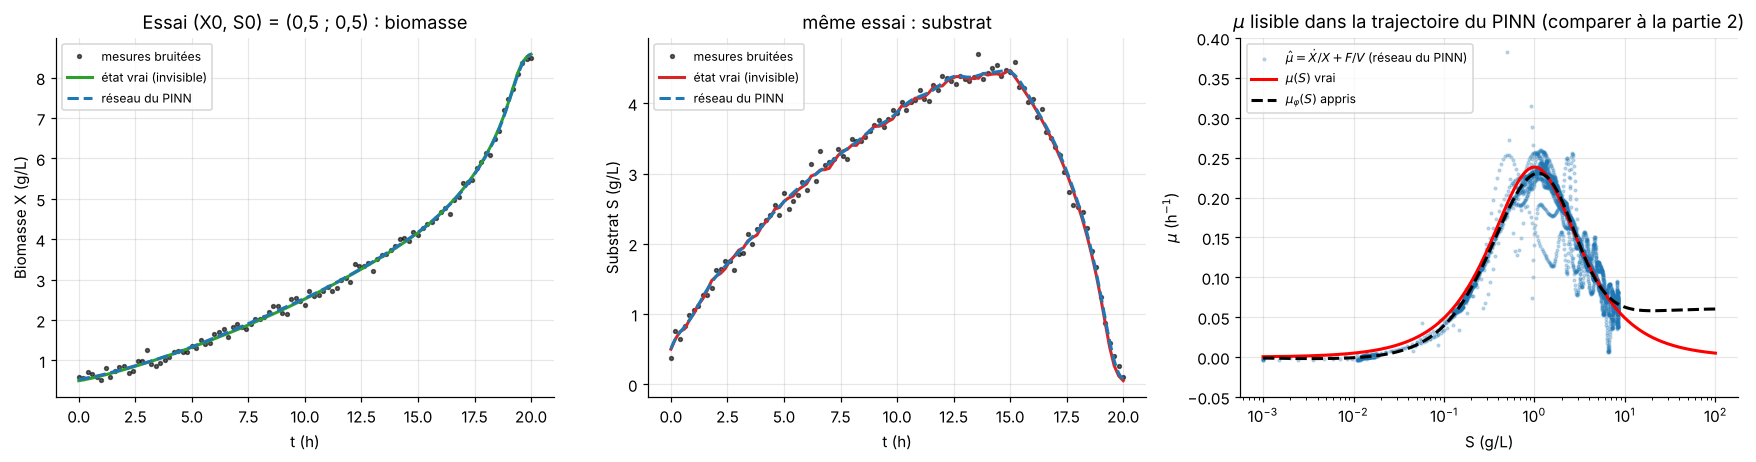

In [10]:
# Ce que le PINN a appris sur un essai d'apprentissage : la trajectoire lissée et le mu qu'elle implique
r_idx = 4; q = train_runs[r_idx]; tt = np.linspace(0, q["t"][-1], 600); Xp, Sp = pinn.X_S(r_idx, tt)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for a, v, vm, vp, nm, c in [(ax[0], "X", "Xm", Xp, "Biomasse X (g/L)", "C2"), (ax[1], "S", "Sm", Sp, "Substrat S (g/L)", "C3")]:
    a.plot(q["t"], q[vm], "k.", ms=5, alpha=0.6, label="mesures bruitées"); a.plot(q["t"], q[v], color=c, lw=2, label="état vrai (invisible)")
    a.plot(tt, vp, "C0--", lw=2, label="réseau du PINN"); a.set_xlabel("t (h)"); a.set_ylabel(nm); a.legend(fontsize=8)
a.set_title("Le PINN lisse le bruit"); ax[0].set_title("Essai (X0, S0) = (0,5 ; 0,5) : biomasse"); ax[1].set_title("même essai : substrat")
# mu lu dans la dérivée de la trajectoire du PINN (tous les essais), au lieu de la différence des mesures bruitées
Smu, Mu = [], []
for r, run in enumerate(pinn.R):
    h_, N_, q_, Np_ = pinn.traj(r, run["tc"], True); X_, S_ = SX * N_[:, 0], SS * N_[:, 1]; Smu.append(S_); Mu.append(SX * Np_[:, 0] / X_ + run["Fc"] / run["Vc"])
Smu, Mu = np.concatenate(Smu), np.concatenate(Mu); Sg = np.logspace(-3, 2, 400)
ax[2].scatter(np.maximum(Smu, 1e-3), Mu, s=3, alpha=0.25, color="C0", label=r"$\hat\mu=\dot X/X+F/V$ (réseau du PINN)")
ax[2].plot(Sg, haldane(Sg), "r", lw=2, label=r"$\mu(S)$ vrai"); ax[2].plot(Sg, pinn.mu_of_S(Sg), "k--", lw=2, label=r"$\mu_\varphi(S)$ appris")
ax[2].set_xscale("log"); ax[2].set_ylim(-0.05, 0.4); ax[2].set_xlabel("S (g/L)"); ax[2].set_ylabel(r"$\mu$ (h$^{-1}$)"); ax[2].legend(fontsize=8, loc="upper left")
ax[2].set_title(r"$\mu$ lisible dans la trajectoire du PINN (comparer à la partie 2)")
plt.tight_layout(); plt.show()

**Lecture.** (Gauche et centre) Le réseau du PINN passe **au milieu** des mesures bruitées et suit l'état vrai, y compris au moment où l'alimentation s'arrête (15 h). (Droite) La vitesse $\hat\mu=\dot X/X+F/V$ lue dans la **dérivée du réseau** est presque confondue avec le $\mu(S)$ vrai, alors que le calcul naïf sur les mesures de la partie 2 était 10 fois trop grand. Le PINN permet donc de « lire » $\mu$ : la physique et la continuité en temps jouent le rôle de filtre. Au-delà de $S\approx8$ g/L (limite des données d'apprentissage), la courbe apprise n'est plus contrainte.

## Évaluation : $\mu_\varphi(S)$ du PINN branché dans les bilans

Même prédicteur que l'hybride série : $(X,S)_{k+1}=$ bilans analytiques avec $\mu=\mu_\varphi(S_k)$. Erreur à un pas (entrées bruitées, cible = état vrai suivant) et erreur en **simulation libre** sur 20 h, départ de l'état initial vrai, pour l'interpolation et l'extrapolation.

In [11]:
pinn_pred = lambda x, s, si, V_, F_: step_phys(x, s, V_, F_, si, pinn.mu_of_S(s))[:2]
models8 = {"Monod seul": monod_pred, "IA pure": bb.predict, "Hybride série (partie 4)": hyb.predict, "PINN (mu appris)": pinn_pred, "Oracle": oracle}
R8 = {nm: dict(os_i=one_step_mse(test_i, pr), os_e=one_step_mse(test_e, pr), fi=free_rmse(test_i, pr), fe=free_rmse(test_e, pr)) for nm, pr in models8.items()}
print(f"{'':<26}{'MSE 1 pas interp':>18}{'MSE 1 pas extrap':>18}{'RMSE X libre interp':>21}{'RMSE X libre extrap':>21}{'dérive (g)':>12}")
for nm, v in R8.items(): print(f"{nm:<26}{v['os_i']:>18.1e}{v['os_e']:>18.1e}{v['fi'][0]:>21.2f}{v['fe'][0]:>21.2f}{drift_max(test_i, v['fi'][2]):>12.2f}")

                            MSE 1 pas interp  MSE 1 pas extrap  RMSE X libre interp  RMSE X libre extrap  dérive (g)
Monod seul                           5.4e-06           5.1e-06                 1.44                 0.36        0.52
IA pure                              6.2e-06           2.5e-04                 2.87                 2.99       63.34
Hybride série (partie 4)             4.9e-06           5.4e-06                 0.82                 0.05        0.27
PINN (mu appris)                     4.9e-06           4.8e-06                 0.07                 0.02        0.00
Oracle                               5.0e-06           4.9e-06                 0.04                 0.03        0.25


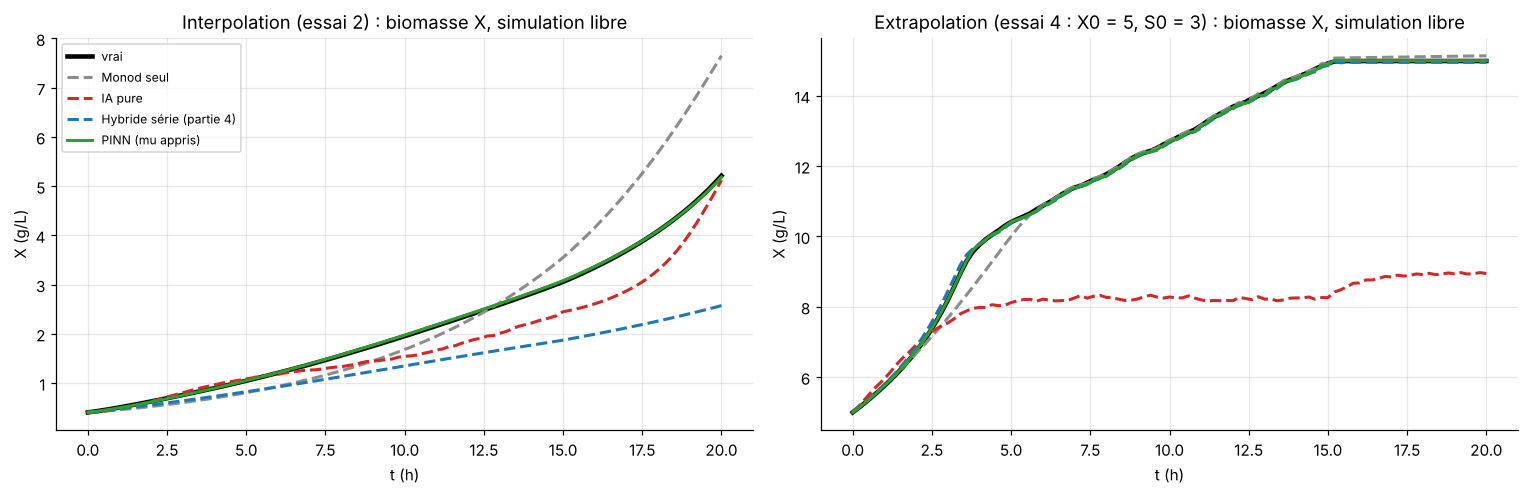

In [12]:
# Figure 1 : trajectoires en simulation libre (un essai d'interpolation et un essai d'extrapolation)
cols8 = {"Monod seul": "0.55", "IA pure": "C3", "Hybride série (partie 4)": "C0", "PINN (mu appris)": "C2"}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for a, runs, key, j, ttl in [(ax[0], test_i, "fi", 1, "Interpolation (essai 2)"), (ax[1], test_e, "fe", 3, "Extrapolation (essai 4 : X0 = 5, S0 = 3)")]:
    q = runs[j]; a.plot(q["t"], q["X"], "k", lw=3, label="vrai")
    for nm in cols8: a.plot(q["t"], R8[nm][key][2][j][0], "--" if nm != "PINN (mu appris)" else "-", color=cols8[nm], lw=2, label=nm)
    a.set_title(ttl + " : biomasse X, simulation libre"); a.set_xlabel("t (h)"); a.set_ylabel("X (g/L)")
ax[0].legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

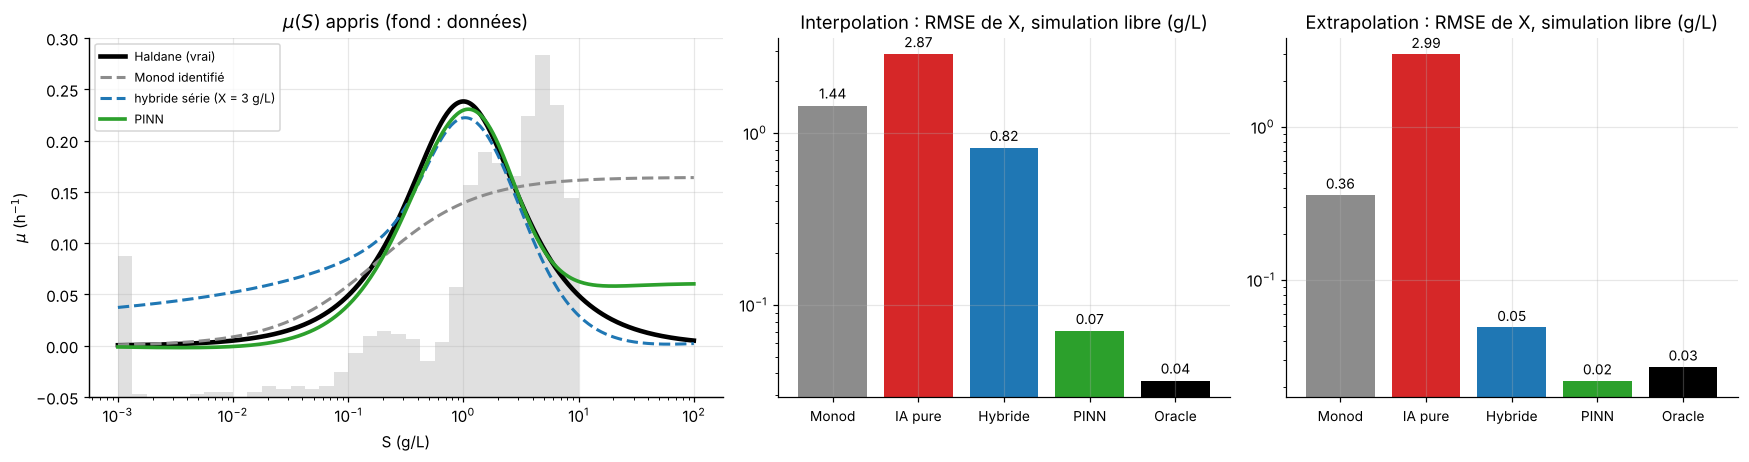

In [13]:
# Figure 2 : mu(S) appris et erreurs globales
Sx = np.logspace(-3, 2, 400)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw=dict(width_ratios=[1.4, 1, 1]))
ax2 = ax[0].twinx(); ax2.hist(dtr["S"], bins=np.logspace(-3, 2, 41), color="0.88", zorder=0); ax2.set_yticks([]); ax2.grid(False)
ax[0].set_zorder(ax2.get_zorder() + 1); ax[0].patch.set_visible(False)
ax[0].plot(Sx, haldane(Sx), "k", lw=3, label="Haldane (vrai)"); ax[0].plot(Sx, monod(Sx, mm, Ks), "--", color="0.55", lw=2, label="Monod identifié")
ax[0].plot(Sx, hyb.mu(np.full_like(Sx, 3.0), Sx), "C0--", lw=2, label="hybride série (X = 3 g/L)"); ax[0].plot(Sx, pinn.mu_of_S(Sx), "C2", lw=2.4, label="PINN")
ax[0].set_xscale("log"); ax[0].set_ylim(-0.05, 0.3); ax[0].set_xlabel("S (g/L)"); ax[0].set_ylabel(r"$\mu$ (h$^{-1}$)"); ax[0].legend(fontsize=8, loc="upper left"); ax[0].set_title(r"$\mu(S)$ appris (fond : données)")
names = ["Monod seul", "IA pure", "Hybride série (partie 4)", "PINN (mu appris)", "Oracle"]; barc = ["0.55", "C3", "C0", "C2", "k"]
for a, key, ttl in [(ax[1], "fi", "Interpolation"), (ax[2], "fe", "Extrapolation")]:
    vals = [R8[n][key][0] for n in names]; a.bar(range(5), vals, color=barc); a.set_yscale("log"); a.set_xticks(range(5)); a.set_xticklabels(["Monod", "IA pure", "Hybride", "PINN", "Oracle"], fontsize=9)
    for i, v_ in enumerate(vals): a.text(i, v_ * 1.1, f"{v_:.2f}", ha="center", fontsize=9)
    a.set_title(f"{ttl} : RMSE de X, simulation libre (g/L)")
plt.tight_layout(); plt.show()

**Lecture.**
- Erreur à un pas : le PINN est au niveau de l'oracle (4,9·10⁻⁶ contre 5,0·10⁻⁶), comme l'hybride série et Monod. Ce critère ne départage toujours pas les modèles.
- **Simulation libre** : avec $\mu_\varphi(S)$ branché dans les bilans, le PINN atteint **0,07 g/L en interpolation** (hybride série : 0,82 ; Monod : 1,44 ; IA pure : 2,87 ; oracle : 0,04) et 0,02 g/L en extrapolation pour cet entraînement (hybride : 0,05).
- La matière est conservée (dérive de l'ordre de $10^{-13}$ g), puisque les bilans sont ceux de la partie 4.
- Figure de gauche : l'essai d'interpolation choisi est celui où l'hybride série de la partie 4 s'écarte le plus ; le PINN suit la trajectoire vraie, Monod et surtout l'IA pure s'en éloignent.
- Figure de droite : la courbe $\mu_\varphi(S)$ du PINN suit Haldane sur toute la plage bien couverte (pic à 1 g/L, branche inhibée, branche des faibles $S$), là où l'hybride série garde un excès de $\mu$ aux faibles $S$. Au-delà de $S\approx6$ g/L, la courbe du PINN se stabilise vers 0,06 au lieu de décroître : cette zone est mal couverte par les données.

**Pourquoi le PINN fait-il mieux ici ? (hypothèse, non testée isolément.)** L'hybride série reçoit l'état **mesuré** (bruité) comme entrée et doit prédire l'état suivant : le bruit d'entrée biaise l'apprentissage de $\mu$ (problème des « erreurs sur les variables »). Le PINN ajuste d'abord une trajectoire **lisse** à tous les instants et n'apprend $\mu$ qu'à partir de cette trajectoire et des bilans, ce qui filtre une partie du bruit.

## Robustesse : autres graines, puis bruit plus élevé

Deux contrôles pour ne pas conclure sur un seul entraînement : (i) **autres initialisations** du PINN ; (ii) un **bruit de 0,3 g/L** (cas où l'hybride série de la partie 7 était mis en difficulté), avec comparaison appariée à l'hybride série et à Monod entraînés sur les mêmes données bruitées.

In [14]:
N_SEEDS = 5          # nombre d'initialisations du PINN testées (graines 0 à 4)
seed_res = []
for sd in range(N_SEEDS):
    net_s = pinn if sd == 0 else train_pinn(train_runs, seed=sd, verbose=False)
    pr = lambda x, s, si, V_, F_, n=net_s: step_phys(x, s, V_, F_, si, n.mu_of_S(s))[:2]
    seed_res.append((free_rmse(test_i, pr)[0], free_rmse(test_e, pr)[0]))
seed_res = np.array(seed_res)
print("RMSE de X en simulation libre (g/L), interpolation / extrapolation, par initialisation :")
for sd, (a_, b_) in enumerate(seed_res): print(f"  graine {sd} : {a_:.2f} / {b_:.2f}")
print(f"Médiane : {np.median(seed_res[:, 0]):.2f} / {np.median(seed_res[:, 1]):.2f}   (hybride série de la partie 4 : {R8['Hybride série (partie 4)']['fi'][0]:.2f} / {R8['Hybride série (partie 4)']['fe'][0]:.2f})")

RMSE de X en simulation libre (g/L), interpolation / extrapolation, par initialisation :
  graine 0 : 0.07 / 0.02
  graine 1 : 0.20 / 1.12
  graine 2 : 0.09 / 0.70
  graine 3 : 0.07 / 0.58
  graine 4 : 0.11 / 0.10
Médiane : 0.09 / 0.58   (hybride série de la partie 4 : 0.82 / 0.05)


In [15]:
sig = 0.3; tr3 = gen_train(sigma=sig); ti3 = gen_test_i(sigma=sig); te3 = gen_test_e(sigma=sig)
pinn3 = train_pinn(tr3, seed=0, sigma=sig, verbose=False)
d3 = patterns_of(tr3); tr_3, va_3 = split(len(d3["X"]), 0); hyb3 = HybridSerie(0); train_model(hyb3, d3, tr_3, va_3); mc3 = fit_monod(d3)
pr3 = {"Monod seul": lambda x, s, si, V_, F_: step_phys(x, s, V_, F_, si, monod(s, *mc3))[:2], "Hybride série (partie 4)": hyb3.predict,
       "PINN (mu appris)": lambda x, s, si, V_, F_: step_phys(x, s, V_, F_, si, pinn3.mu_of_S(s))[:2]}
print(f"Bruit de {sig} g/L : RMSE de X en simulation libre (g/L)")
print(f"{'':<26}{'interpolation':>15}{'extrapolation':>15}")
for nm, pr in pr3.items(): print(f"{nm:<26}{free_rmse(ti3, pr)[0]:>15.2f}{free_rmse(te3, pr)[0]:>15.2f}")

Bruit de 0.3 g/L : RMSE de X en simulation libre (g/L)
                            interpolation  extrapolation
Monod seul                           1.54           0.41
Hybride série (partie 4)             4.07           1.04
PINN (mu appris)                     1.69           0.61


**Lecture.**
- **Interpolation : stable.** Sur 5 initialisations, l'erreur reste entre 0,07 et 0,20 g/L (médiane 0,09), soit 4 à 12 fois mieux que l'hybride série (0,82).
- **Extrapolation : instable.** Selon l'initialisation, l'erreur va de 0,02 à 1,12 g/L (médiane 0,58, supérieure à celle de Monod seul : 0,36). Le résultat à 0,02 g/L de la figure précédente est donc le **meilleur** des 5 cas, pas un cas typique.
- **Cause probable.** Dans une initialisation défavorable, le $\mu_\varphi(S)$ est correct sur toute la plage bien couverte mais faux aux **très faibles $S$** (par exemple 0,039 h⁻¹ à $S=0{,}003$ g/L, contre 0,0015 pour Haldane). Peu de données y renseignent $\mu$, et les essais d'extrapolation, avec une biomasse de 2 à 6 g/L, y sont très sensibles. C'est cohérent avec les erreurs observées, mais je ne l'ai pas démontré par une expérience dédiée.
- **Bruit à 0,3 g/L** (un seul entraînement) : le PINN (1,69 / 0,61) fait **mieux que l'hybride série** (4,07 / 1,04) mais **pas mieux que Monod seul** (1,54 / 0,41).

> *Note : les chiffres ci-dessus (médianes 0,09 / 0,58) viennent des 5 initialisations (graines 0 à 4) exécutées par ce notebook, à environ 1 min chacune.*

## Conclusion de la partie 8

1. **Le PINN est un bon identificateur de $\mu(S)$** : branché dans les bilans, il donne en interpolation une erreur de 0,07 à 0,20 g/L sur 5 initialisations, contre 0,82 pour l'hybride série, et conserve la matière.
2. **Son avantage vient probablement du filtrage du bruit** (trajectoire lisse + physique) ; c'est une hypothèse cohérente avec le bruit à 0,3 g/L (meilleur que l'hybride série), mais il ne bat toujours pas Monod seul dans ce cas.
3. **Il n'est pas plus robuste en extrapolation** : de 0,02 à 1,12 g/L selon l'initialisation (médiane 0,58). La physique dans le critère n'est pas la physique dans la structure : ce qu'il apprend mal reste mal contraint.
4. **Il coûte plus cher** : environ 1 400 paramètres, une minute d'entraînement (contre quelques secondes pour l'hybride série), des séries temporelles complètes, F(t) et S_in(t) connus à tout instant, un gradient du second ordre écrit à la main, et des réglages ($\lambda$, $\rho$, continuation). Ces réglages ont été fixés **une seule fois**, sans les ajuster sur les jeux de test ; une exploration plus poussée pourrait réduire la dispersion en extrapolation.
5. **Comparaison à nuancer** : le PINN utilise des informations que l'hybride série n'utilise pas (les instants de mesure, le niveau de bruit $\sigma$, des réseaux par essai). Ce n'est donc pas une comparaison « à information égale ».

**Message à retenir** : mettre la physique dans le critère aide à filtrer le bruit et à identifier la cinétique, mais ne garantit ni la robustesse hors domaine ni un gain systématique sur un hybride bien structuré.